
# Cento Nuptialis Line-Based Metrical Stylometry with LambdaG

This notebook analyses the stylistic affinities of Ausonius's *Cento Nuptialis* using
LambdaG authorship verification (uncalibrated) on **line-based metrical number-mapped sentences**.

Unlike the sentence-based metrical model (`cento_metrical_stylometry.ipynb`), which uses
syntax-driven sentence boundaries, this model defines "sentences" purely by hexameter line
boundaries. Each line's words are replaced by their prime-encoded metrical numbers directly
from the source scansion data, without any sentence splitting.

## Setup

The on-disk model files contain one sentence per hexameter line (N=1).  Overlapping
corpora of N=2 and N=4 lines are built dynamically in this notebook.

Four model corpora are compared against the cento:
- **vergil**: Vergil, *Georgics* (4 books)
- **aeneid**: Vergil, *Aeneid* (12 books)
- **ausonius**: Ausonius hexameter works (17 works, excluding cento)
- **background**: Ovid, Lucan, Silius Italicus, Valerius Flaccus (50 books)

All corpora contain `*.mapped_lines.txt` files produced by `scripts/generate_metrical_lines.py`.
Each word is replaced by its prime-encoded metrical position number, and every line ends
with an `<EOL>` marker.


In [1]:

from __future__ import annotations

import re
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from sentence_corpora import Sentence, TwoLevelCorpus
from sentence_corpora.lambdag import LambdaGAV



## Load Corpora

Each directory contains `*.mapped_lines.txt` files. We parse the
filenames to extract `(author, work)` metadata and build `TwoLevelCorpus` objects.

For N=2 and N=4, we build overlapping corpora dynamically from the unit sentences:
- N=2: sliding window of 2 lines, stepping by 1 (lines 1–2, 2–3, 3–4, …)
- N=4: sliding window of 4 lines, stepping by 1 (lines 1–4, 2–5, 3–6, …)

Each window joins the constituent lines with `<EOL>` and appends a final `<EOL>`.


In [2]:

def parse_filename(path: Path) -> tuple[str, str]:
    """Parse '<name>.mapped_lines.txt' into (author, work).

    Filenames from metrical_model_lines/ follow the pattern:
      - ausonius: ausonius_caesares.mapped_lines.txt  →  ('ausonius', 'caesares')
      - vergil: vergil_georgics_1.mapped_lines.txt  →  ('vergil', 'georgics_1')
      - aeneid: vergil_aeneid_1.mapped_lines.txt  →  ('vergil', 'aeneid_1')
      - background: ovid_metamorphoses_1.mapped_lines.txt  →  ('ovid', 'metamorphoses_1')
    """
    name = re.sub(r"\.mapped_lines\.txt$", "", path.name)
    parts = name.split("_", 1)
    if len(parts) == 1:
        return parts[0], ""
    return parts[0], parts[1]


def load_corpus(data_dir: Path) -> TwoLevelCorpus:
    """Read all *.mapped_lines.txt files and return a TwoLevelCorpus."""
    sentences = []
    for path in sorted(data_dir.glob("*.mapped_lines.txt")):
        author, work = parse_filename(path)
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    sentences.append(Sentence(text=line, metadata={"author": author, "work": work}))
    return TwoLevelCorpus(sentences, levels=["author", "work"])


def build_overlapping_corpus(
    corpus: TwoLevelCorpus,
    window_size: int,
) -> TwoLevelCorpus:
    """Build a sliding-window overlapping corpus from a unit corpus.

    Groups sentences by (author, work), then for each group creates
    sliding windows of `window_size` sentences, joining them with <EOL>.

    Returns a new TwoLevelCorpus with the overlapping sentences.
    """
    # Group sentences by (author, work)
    groups: dict[tuple[str, str], list[Sentence]] = {}
    for sent in corpus:
        key = (sent.metadata["author"], sent.metadata["work"])
        groups.setdefault(key, []).append(sent)

    overlapping = []
    for (author, work), sents in sorted(groups.items()):
        for i in range(len(sents) - window_size + 1):
            window = sents[i : i + window_size]
            # Join the <EOL>-terminated lines into one sentence
            # Each unit sentence already ends with <EOL>, so just concatenate tokens
            tokens = []
            for s in window:
                tokens.extend(s.text.split())
            overlapping.append(
                Sentence(text=" ".join(tokens), metadata={"author": author, "work": work})
            )

    return TwoLevelCorpus(overlapping, levels=["author", "work"])


def load_plain_sentences(path: Path) -> list[str]:
    """Load sentences as list of raw text strings."""
    with open(path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]


def to_sentence_lists(corpus: TwoLevelCorpus) -> list[list[str]]:
    """Tokenise corpus sentences into list of token lists."""
    return [s.text.split() for s in corpus]


def corpus_stats(corpus: TwoLevelCorpus, label: str) -> None:
    """Print summary statistics for a corpus."""
    print(f"{label}: {len(corpus)} sentences, {sum(len(s.text.split()) for s in corpus)} tokens")


def sample_corpus_to_token_count(
    corpus: TwoLevelCorpus,
    target_tokens: int,
    rng: Any,
) -> TwoLevelCorpus:
    """Sample sentences from corpus until we reach approximately target_tokens."""
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)
    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )
    shuffled = list(sentences)
    rng.shuffle(shuffled)
    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break
    return type(corpus)(sampled, levels=corpus.levels)


# Load the unit (N=1) model corpora
unit_vergil = load_corpus(Path("metrical_model_lines/vergil"))
unit_aeneid = load_corpus(Path("metrical_model_lines/aeneid"))
unit_ausonius = load_corpus(Path("metrical_model_lines/ausonius"))
unit_background = load_corpus(Path("metrical_model_lines/background"))
unit_cento = load_corpus(Path("metrical_model_lines/question"))

print("Unit (N=1) corpora:")
corpus_stats(unit_vergil, "Vergil (Georgics)")
corpus_stats(unit_aeneid, "Aeneid")
corpus_stats(unit_ausonius, "Ausonius")
corpus_stats(unit_background, "Background")
corpus_stats(unit_cento, "Cento (question)")


Unit (N=1) corpora:
Vergil (Georgics): 2187 sentences, 16360 tokens
Aeneid: 9896 sentences, 73663 tokens
Ausonius: 2247 sentences, 16396 tokens
Background: 37840 sentences, 280477 tokens
Cento (question): 131 sentences, 955 tokens



## Run LambdaG Authorship Verification (Uncalibrated)

For each window size (N=1, N=2, N=4) and each candidate author, we run a single AV problem:
- **q_corpus**: the cento (question text)
- **kr_corpus**: the model corpus (known reference) + background (impostors)
- **known_entity**: the author label in the model corpus

The `LambdaGAV.run_single_av_problem` method computes a raw score indicating
how similar the question text is to the known author. Higher scores = more similar.


In [3]:

# Run LambdaG AV for all three window sizes
WINDOW_SIZES = [1, 2, 4]
av = LambdaGAV()
rng = np.random.default_rng(42)

all_results = []

for n in WINDOW_SIZES:
    print(f"\n{'='*60}")
    print(f"Window size N={n}")
    print(f"{'='*60}")

    if n == 1:
        vergil_corpus = unit_vergil
        aeneid_corpus_n = unit_aeneid
        ausonius_corpus = unit_ausonius
        background_corpus = unit_background
        cento_corpus = unit_cento
    else:
        vergil_corpus = build_overlapping_corpus(unit_vergil, n)
        aeneid_corpus_n = build_overlapping_corpus(unit_aeneid, n)
        ausonius_corpus = build_overlapping_corpus(unit_ausonius, n)
        background_corpus = build_overlapping_corpus(unit_background, n)
        cento_corpus = build_overlapping_corpus(unit_cento, n)

    corpus_stats(vergil_corpus, f"  Vergil (N={n})")
    corpus_stats(ausonius_corpus, f"  Ausonius (N={n})")
    corpus_stats(background_corpus, f"  Background (N={n})")
    corpus_stats(cento_corpus, f"  Cento (N={n})")

    for candidate, candidate_corpus in [("vergil", vergil_corpus), ("ausonius", ausonius_corpus)]:
        kr_sentences = list(candidate_corpus) + list(background_corpus)
        kr_corpus = TwoLevelCorpus(kr_sentences, levels=["author", "work"])

        result = av.run_single_av_problem(
            known_entity=candidate,
            q_corpus=cento_corpus,
            kr_corpus=kr_corpus,
            known_tokens=15000,
            reference_tokens=30000,
            order=10,
            num_references=50,
            rng=rng,
        )

        all_results.append({
            "window_size": n,
            "candidate": candidate,
            "score": result.get("score", 0.0),
            "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
            "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
            "n_unknown": result.get("unknown_sentences_used", 0),
            "unknown_tokens": result.get("unknown_tokens_used", 0),
            "n_known": result.get("known_sentences_used", 0),
            "n_reference": result.get("reference_sentences_used", 0),
            "error": result.get("error", None),
        })
        print(f"  {candidate}: score={all_results[-1]['score']:.4f}, tokens_q={all_results[-1]['unknown_tokens']}")

print("\nDone.")



Window size N=1
  Vergil (N=1): 2187 sentences, 16360 tokens
  Ausonius (N=1): 2247 sentences, 16396 tokens
  Background (N=1): 37840 sentences, 280477 tokens
  Cento (N=1): 131 sentences, 955 tokens
  vergil: score=111.7678, tokens_q=955
  ausonius: score=-37.1014, tokens_q=955

Window size N=2
  Vergil (N=2): 2183 sentences, 32659 tokens
  Ausonius (N=2): 2230 sentences, 32543 tokens
  Background (N=2): 37790 sentences, 560226 tokens
  Cento (N=2): 130 sentences, 1896 tokens
  vergil: score=72.5722, tokens_q=1896
  ausonius: score=-204.4568, tokens_q=1896

Window size N=4
  Vergil (N=4): 2175 sentences, 65085 tokens
  Ausonius (N=4): 2196 sentences, 64091 tokens
  Background (N=4): 37690 sentences, 1117546 tokens
  Cento (N=4): 128 sentences, 3735 tokens
  vergil: score=209.6328, tokens_q=3735
  ausonius: score=-189.0156, tokens_q=3735

Done.



## Results


In [4]:

df = pd.DataFrame(all_results)
df = df.sort_values(["window_size", "candidate"], ascending=[True, False])

PRIOR = 0.5
df["prob_sqrt"] = df["corrected_score_sqrt"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)
df["prob_hapax"] = df["corrected_score_hapax"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)

print("LambdaG Line-Based Metrical Results (uncalibrated, prior=0.5):")
print("=" * 100)
for n in WINDOW_SIZES:
    subset = df[df["window_size"] == n]
    print(f"\n  N={n}:")
    for _, row in subset.iterrows():
        print(f"    {row['candidate']:<12}  raw={row['score']:>8.4f}"
              f"  sqrt={row['corrected_score_sqrt']:>8.4f} -> {row['prob_sqrt']:>6.1f}%"
              f"  hapax={row['corrected_score_hapax']:>8.4f} -> {row['prob_hapax']:>6.1f}%"
              f"  (q_tokens={row['unknown_tokens']})")


LambdaG Line-Based Metrical Results (uncalibrated, prior=0.5):

  N=1:
    vergil        raw=111.7678  sqrt=  3.6167 ->   97.4%  hapax=  1.0533 ->   74.1%  (q_tokens=955)
    ausonius      raw=-37.1014  sqrt= -1.2006 ->   23.1%  hapax= -0.3496 ->   41.3%  (q_tokens=955)

  N=2:
    vergil        raw= 72.5722  sqrt=  1.6667 ->   84.1%  hapax=  0.0000 ->   50.0%  (q_tokens=1896)
    ausonius      raw=-204.4568  sqrt= -4.6955 ->    0.9%  hapax= -0.0000 ->   50.0%  (q_tokens=1896)

  N=4:
    vergil        raw=209.6328  sqrt=  3.4302 ->   96.9%  hapax=  0.0000 ->   50.0%  (q_tokens=3735)
    ausonius      raw=-189.0156  sqrt= -3.0928 ->    4.3%  hapax= -0.0000 ->   50.0%  (q_tokens=3735)



## Aeneid vs Vergil (Georgics) — Baseline Check

Sample ~1013 tokens from Aeneid, compare against Vergil (Georgics) + Background.
100 iterations using Ray for parallelism.


In [5]:

import ray
from tqdm import tqdm

# Use N=1 for the baseline (unit sentences)
TARGET_TOKENS = 1013
NUM_ITERATIONS = 100

# KR corpus = vergil (Georgics) + background (unit sentences)
kr_sentences = list(unit_vergil) + list(unit_background)
kr_corpus = TwoLevelCorpus(kr_sentences, levels=["author", "work"])

print(f"Aeneid corpus: {len(unit_aeneid)} sentences, {sum(len(s.text.split()) for s in unit_aeneid)} tokens")


@ray.remote
def run_aeneid_iteration(i: int) -> dict:
    """Run a single Aeneid vs Vergil AV iteration."""
    iter_rng = np.random.default_rng(42 + i)
    q_corpus = sample_corpus_to_token_count(unit_aeneid, TARGET_TOKENS, iter_rng)
    actual_tokens = sum(len(s.text.split()) for s in q_corpus)

    av = LambdaGAV()
    result = av.run_single_av_problem(
        known_entity="vergil",
        q_corpus=q_corpus,
        kr_corpus=kr_corpus,
        known_tokens=15000,
        reference_tokens=30000,
        order=10,
        num_references=10,
        rng=iter_rng,
    )

    return {
        "iteration": i,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "q_tokens": actual_tokens,
        "n_known": result.get("known_sentences_used", 0),
        "n_reference": result.get("reference_sentences_used", 0),
        "error": result.get("error", None),
    }


ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

tasks = [run_aeneid_iteration.remote(i) for i in range(NUM_ITERATIONS)]

aeneid_results = []
for _ in tqdm(range(len(tasks)), desc="Aeneid AV"):
    ready, tasks = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    aeneid_results.append(result)

ray.shutdown()
print("\nDone.")


Aeneid corpus: 9896 sentences, 73663 tokens


2026-07-30 13:33:59,644	INFO worker.py:2024 -- Started a local Ray instance.


Ray initialized with 10.0 CPUs


Aeneid AV: 100%|██████████| 100/100 [01:25<00:00,  1.16it/s]



Done.


In [6]:

df_aeneid = pd.DataFrame(aeneid_results)

PRIOR = 0.5
df_aeneid["prob_sqrt"] = df_aeneid["corrected_score_sqrt"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)
df_aeneid["prob_hapax"] = df_aeneid["corrected_score_hapax"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)

print(f"Aeneid vs Vergil (Georgics) — {NUM_ITERATIONS} iterations, ~{TARGET_TOKENS} tokens each, prior={PRIOR}")
print("=" * 100)
print(f"{'iter':>4}  {'raw':>8}  {'sqrt':>8}  {'prob_sqrt':>10}  {'hapax':>8}  {'prob_hapax':>10}  {'q_tok':>6}")
print("-" * 100)
for _, row in df_aeneid.iterrows():
    print(f"  {int(row['iteration']):>2}  {row['score']:>8.4f}  {row['corrected_score_sqrt']:>8.4f}"
          f"  {row['prob_sqrt']:>9.1f}%  {row['corrected_score_hapax']:>8.4f}"
          f"  {row['prob_hapax']:>9.1f}%  {int(row['q_tokens']):>6}")
print("-" * 100)
print(f"{'mean':>4}  {df_aeneid['score'].mean():>8.4f}  {df_aeneid['corrected_score_sqrt'].mean():>8.4f}"
      f"  {df_aeneid['prob_sqrt'].mean():>9.1f}%  {df_aeneid['corrected_score_hapax'].mean():>8.4f}"
      f"  {df_aeneid['prob_hapax'].mean():>9.1f}%")
print(f"{'std':>4}  {df_aeneid['score'].std():>8.4f}  {df_aeneid['corrected_score_sqrt'].std():>8.4f}"
      f"  {df_aeneid['prob_sqrt'].std():>9.1f}%  {df_aeneid['corrected_score_hapax'].std():>8.4f}"
      f"  {df_aeneid['prob_hapax'].std():>9.1f}%")


Aeneid vs Vergil (Georgics) — 100 iterations, ~1013 tokens each, prior=0.5
iter       raw      sqrt   prob_sqrt     hapax  prob_hapax   q_tok
----------------------------------------------------------------------------------------------------
   1  150.9409    4.7401       99.1%    0.4466       61.0%    1014
   9  194.0598    6.0852       99.8%    1.3357       79.2%    1017
   2   -9.0167   -0.2830       43.0%   -0.0711       48.2%    1015
   8  240.9641    7.5560       99.9%    1.6586       84.0%    1017
   3   82.7188    2.5964       93.1%    0.8150       69.3%    1015
   7   19.5520    0.6140       64.9%    0.2314       55.8%    1014
   6  127.0900    3.9911       98.2%    0.6267       65.2%    1014
   5  115.4137    3.6244       97.4%    0.7967       68.9%    1014
   0   41.1536    1.2905       78.4%    0.2833       57.0%    1017
   4  117.3271    3.6791       97.5%    0.2307       55.7%    1017
  10  109.6550    3.4436       96.9%    0.4326       60.6%    1014
  11   39.4684    1.


## Mosella vs Ausonius — Internal Baseline


In [7]:

# Build Mosella corpus (q) and Ausonius-minus-Mosella corpus (kr) — N=1 unit sentences
mosella_sentences = [s for s in unit_ausonius if s.work == "mosella"]
ausonius_no_mosella_sentences = [s for s in unit_ausonius if s.work != "mosella"]

mosella_corpus = TwoLevelCorpus(mosella_sentences, levels=["author", "work"])
ausonius_no_mosella = TwoLevelCorpus(ausonius_no_mosella_sentences, levels=["author", "work"])

# KR corpus = ausonius (without mosella) + background
kr_ausonius_sentences = list(ausonius_no_mosella) + list(unit_background)
kr_ausonius_corpus = TwoLevelCorpus(kr_ausonius_sentences, levels=["author", "work"])

print(f"Mosella corpus: {len(mosella_corpus)} sentences, {sum(len(s.text.split()) for s in mosella_corpus)} tokens")
print(f"Ausonius (excl. Mosella): {len(ausonius_no_mosella)} sentences, {sum(len(s.text.split()) for s in ausonius_no_mosella)} tokens")
print(f"KR corpus (Ausonius excl. Mosella + background): {len(kr_ausonius_corpus)} sentences")


@ray.remote
def run_mosella_iteration(i: int) -> dict:
    """Run a single Mosella vs Ausonius AV iteration."""
    iter_rng = np.random.default_rng(100 + i)
    q_corpus = sample_corpus_to_token_count(mosella_corpus, TARGET_TOKENS, iter_rng)
    actual_tokens = sum(len(s.text.split()) for s in q_corpus)

    av = LambdaGAV()
    result = av.run_single_av_problem(
        known_entity="ausonius",
        q_corpus=q_corpus,
        kr_corpus=kr_ausonius_corpus,
        known_tokens=13000,
        reference_tokens=20000,
        order=10,
        num_references=10,
        rng=iter_rng,
    )

    return {
        "iteration": i,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "q_tokens": actual_tokens,
        "n_known": result.get("known_sentences_used", 0),
        "n_reference": result.get("reference_sentences_used", 0),
        "error": result.get("error", None),
    }


ray.init(ignore_reinit_error=True)

tasks = [run_mosella_iteration.remote(i) for i in range(NUM_ITERATIONS)]

mosella_results = []
for _ in tqdm(range(len(tasks)), desc="Mosella AV"):
    ready, tasks = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    mosella_results.append(result)

ray.shutdown()
print("\nDone.")


Mosella corpus: 482 sentences, 3414 tokens
Ausonius (excl. Mosella): 1765 sentences, 12982 tokens
KR corpus (Ausonius excl. Mosella + background): 39605 sentences


2026-07-30 13:35:47,467	INFO worker.py:2024 -- Started a local Ray instance.
Mosella AV: 100%|██████████| 100/100 [01:15<00:00,  1.32it/s]



Done.


In [8]:

df_mosella = pd.DataFrame(mosella_results)

df_mosella["prob_sqrt"] = df_mosella["corrected_score_sqrt"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)
df_mosella["prob_hapax"] = df_mosella["corrected_score_hapax"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)

print(f"Mosella vs Ausonius — {NUM_ITERATIONS} iterations, ~{TARGET_TOKENS} tokens each, prior={PRIOR}")
print("=" * 100)
print(f"{'iter':>4}  {'raw':>8}  {'sqrt':>8}  {'prob_sqrt':>10}  {'hapax':>8}  {'prob_hapax':>10}  {'q_tok':>6}")
print("-" * 100)
for _, row in df_mosella.iterrows():
    print(f"  {int(row['iteration']):>2}  {row['score']:>8.4f}  {row['corrected_score_sqrt']:>8.4f}"
          f"  {row['prob_sqrt']:>9.1f}%  {row['corrected_score_hapax']:>8.4f}"
          f"  {row['prob_hapax']:>9.1f}%  {int(row['q_tokens']):>6}")
print("-" * 100)
print(f"{'mean':>4}  {df_mosella['score'].mean():>8.4f}  {df_mosella['corrected_score_sqrt'].mean():>8.4f}"
      f"  {df_mosella['prob_sqrt'].mean():>9.1f}%  {df_mosella['corrected_score_hapax'].mean():>8.4f}"
      f"  {df_mosella['prob_hapax'].mean():>9.1f}%")
print(f"{'std':>4}  {df_mosella['score'].std():>8.4f}  {df_mosella['corrected_score_sqrt'].std():>8.4f}"
      f"  {df_mosella['prob_sqrt'].std():>9.1f}%  {df_mosella['corrected_score_hapax'].std():>8.4f}"
      f"  {df_mosella['prob_hapax'].std():>9.1f}%")


Mosella vs Ausonius — 100 iterations, ~1013 tokens each, prior=0.5
iter       raw      sqrt   prob_sqrt     hapax  prob_hapax   q_tok
----------------------------------------------------------------------------------------------------
   0  123.9470    3.8924       98.0%    0.9779       72.7%    1014
   9  125.6646    3.9405       98.1%    0.4943       62.1%    1017
   3  138.5508    4.3446       98.7%    0.9536       72.2%    1017
   4   44.8639    1.4041       80.3%    0.3955       59.8%    1021
   2   -4.5730   -0.1435       46.4%   -0.0451       48.9%    1015
   1  -21.5483   -0.6770       33.7%   -0.1276       46.8%    1013
   5   13.6729    0.4283       60.5%    0.0939       52.3%    1019
   6    6.9498    0.2181       55.4%    0.0753       51.9%    1015
   8  119.2139    3.7382       97.7%    0.8205       69.4%    1017
   7   16.8127    0.5272       62.9%    0.1323       53.3%    1017
  10  111.7742    3.5067       97.1%    0.7701       68.4%    1016
  16   37.4997    1.1759    


## Visualisation: Baseline Score Distributions with Cento Markers (N=4)


Font name: `Roboto Condensed`


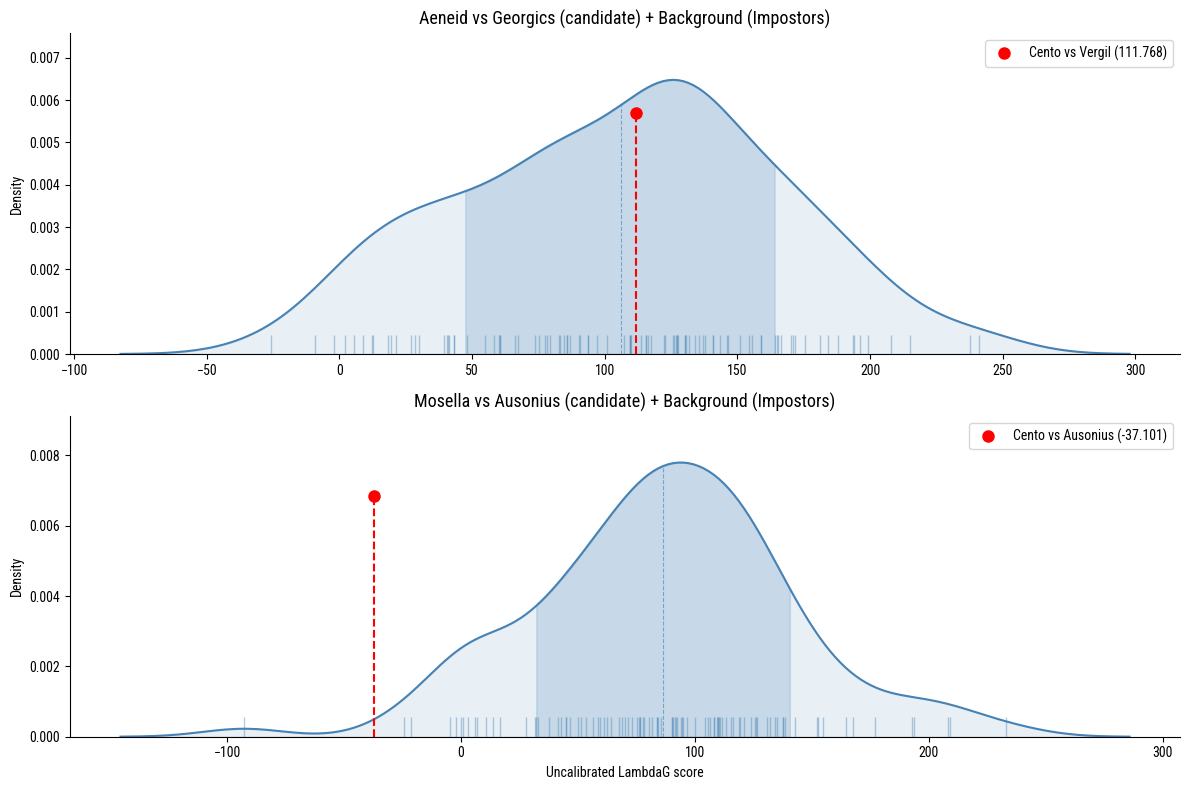

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import mpl_fontkit as fk

fk.install("Roboto Condensed")
plt.rcParams["font.family"] = "Roboto Condensed"

# Get cento scores for N=4
cento_vergil_score = df.loc[
    (df["window_size"] == 4) & (df["candidate"] == "vergil"), "score"
].values[0]
cento_ausonius_score = df.loc[
    (df["window_size"] == 4) & (df["candidate"] == "ausonius"), "score"
].values[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))


def plot_baseline(ax, data, cento_score, title, candidate, xlabel=""):
    scores = data["score"]
    mean = scores.mean()
    sd = scores.std()

    sns.kdeplot(data=data, x="score", ax=ax, color="steelblue",
                linewidth=1.5, fill=False, bw_adjust=0.8)
    sns.rugplot(data=data, x="score", ax=ax, color="steelblue",
                alpha=0.4, height=0.06)

    line = ax.lines[0]
    x_data, y_data = line.get_data()

    ax.fill_between(x_data, y_data, alpha=0.12, color="steelblue")

    mask = (np.array(x_data) >= mean - sd) & (np.array(x_data) <= mean + sd)
    ax.fill_between(np.array(x_data)[mask], np.array(y_data)[mask],
                    alpha=0.2, color="steelblue")

    mean_y = float(np.interp(mean, x_data, y_data))
    ax.vlines(mean, 0, mean_y, colors="steelblue", linewidth=0.8,
              linestyles="--", alpha=0.6)

    ax.axvline(cento_score, ymax=0.75, color="red", linewidth=1.5, linestyle="--")
    cento_y = ax.get_ylim()[1] * 0.75
    ax.plot(cento_score, cento_y, "o", color="red", markersize=8,
            label=f"Cento vs {candidate} ({cento_score:.3f})")

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=10, loc="upper right")
    sns.despine(ax=ax)


plot_baseline(axes[0], df_aeneid, cento_vergil_score,
              "Aeneid vs Georgics (candidate) + Background (Impostors)", "Vergil")

plot_baseline(axes[1], df_mosella, cento_ausonius_score,
              "Mosella vs Ausonius (candidate) + Background (Impostors)", "Ausonius",
              xlabel="Uncalibrated LambdaG score")

plt.tight_layout()
plt.show()



## Per-Sentence LambdaG Visualization (N=4)

Run `lambdaG_visualize` on the full cento against Vergil using N=4 overlapping
sentences, then render the raw HTML output. Token colours and circle colours are
set by lambdaG itself — red/warm = positive (similar), blue = negative (dissimilar).

Pipe tokens (`|`) are stripped from the unmasked text so they don't corrupt
the token-position matching between masked and unmasked views.

The unmasked (Latin) text is built from the plain verse-per-line files in
`processed/`, grouped into the same N=4 sliding windows as the metrical data.


In [10]:

from IPython.display import IFrame
from lambdag.visualize import lambdaG_visualize
import base64


def strip_pipes(sentences: list[str]) -> list[str]:
    """Remove pipe markers from sentence strings."""
    return [s.replace(" | ", "| ").strip() for s in sentences]


def run_lambdag(q_text, unmasked, k_text, ref_text, negative, rng):
    """Run lambdaG_visualize and return the raw result dict."""
    return lambdaG_visualize(
        q_text=q_text,
        k_text=k_text,
        ref_text=ref_text,
        N=10, r=30,
        output="html",
        scale="relative",
        negative=negative,
        order_by="importance",
        unmasked_sentences=unmasked,
        rng=rng,
    )


def render_full(result: dict, title: str, n_sentences: int) -> IFrame:
    """Render the raw lambdaG HTML output (full poem) in an IFrame."""
    html = result["colourcoded_text"]
    html = html.replace("<EOL>", "&#60;EOL&#62;")
    output_html = (
        '<!DOCTYPE html><html lang="en"><head><meta charset="UTF-8">'
        '<link href="https://fonts.googleapis.com/css2?family=Roboto+Condensed:wght@300;400;700&display=swap" rel="stylesheet">'
        "<style>"
        "body{font-family:'Roboto Condensed',sans-serif;margin:0;padding:20px;background:#f5f5f5;font-weight:300}"
        "h2{text-align:center;color:#333;font-weight:700}"
        ".subtitle{text-align:center;color:#666;margin-bottom:20px;font-size:14px}"
        "</style></head><body>"
        f"<h2>{title}</h2>"
        f"<p class='subtitle'>{n_sentences} sentences, token-level LambdaG, relative scale, ordered by importance</p>"
        + html + "</body></html>"
    )
    html_bytes = output_html.encode("utf-8")
    html_b64 = base64.b64encode(html_bytes).decode("utf-8")
    return IFrame(f"data:text/html;base64,{html_b64}", width="100%", height=800)


def extract_sentence_rows(html: str) -> list[str]:
    """Extract sentence-row divs from lambdaG HTML output."""
    return re.findall(
        r'<div class="sentence-row">.*?</div>\s*</div>', html, re.DOTALL
    )


def render_rows(rows: list[str], title: str, subtitle: str = "") -> IFrame:
    """Wrap extracted sentence-row divs in a styled HTML page and return IFrame."""
    html = "\n".join(rows).replace("<EOL>", "&#60;EOL&#62;")
    subtitle_html = f"<p class='subtitle'>{subtitle}</p>" if subtitle else ""
    output_html = (
        '<!DOCTYPE html><html lang="en"><head><meta charset="UTF-8">'
        '<link href="https://fonts.googleapis.com/css2?family=Roboto+Condensed:wght@300;400;700&display=swap" rel="stylesheet">'
        "<style>"
        "body{font-family:'Roboto Condensed',sans-serif;margin:0;padding:20px;background:#f5f5f5;font-weight:300}"
        "h2{text-align:center;color:#333;font-weight:700}"
        ".subtitle{text-align:center;color:#666;margin-bottom:20px;font-size:14px}"
        ".sentence-row{display:flex;align-items:flex-start;margin-bottom:12px;gap:10px}"
        ".sentence-column{flex:1;line-height:1.6;font-size:15px}"
        ".sentence-number-circle{display:inline-block;width:28px;height:28px;line-height:28px;border-radius:50%;text-align:center;font-size:12px;font-weight:700}"
        ".heading-row{display:flex;align-items:center;margin-bottom:10px;gap:10px}"
        ".heading-spacer{width:38px;flex-shrink:0}"
        ".column-heading{flex:1;text-align:center;color:#555;font-size:1.2em;font-weight:400;border-bottom:2px solid #ddd;padding-bottom:10px}"
        "</style></head><body>"
        f"<h2>{title}</h2>"
        f"{subtitle_html}"
        '<div class="heading-row"><div class="heading-spacer"></div>'
        '<div class="column-heading">Masked (Metrical Numbers)</div>'
        '<div class="column-heading">Unmasked (Latin Text)</div>'
        "</div>" + html + "</body></html>"
    )
    html_bytes = output_html.encode("utf-8")
    html_b64 = base64.b64encode(html_bytes).decode("utf-8")
    return IFrame(f"data:text/html;base64,{html_b64}", width="100%", height=800)


def top_n(result: dict, n: int, title: str) -> IFrame:
    """Extract the top N sentences (most similar = first in order_by=importance)."""
    rows = extract_sentence_rows(result["colourcoded_text"])[:n]
    return render_rows(rows, title, f"Top {n} sentences (highest lambdaG)")


def bottom_n(result: dict, n: int, title: str) -> IFrame:
    """Extract the bottom N sentences (least similar = last in order_by=importance)."""
    rows = extract_sentence_rows(result["colourcoded_text"])[-n:]
    rows = list(reversed(rows))  # most dissimilar first
    return render_rows(rows, title, f"Bottom {n} sentences (lowest lambdaG)")


In [ ]:

# Build N=4 overlapping corpora for visualization
VIS_N = 4

cento_n4 = build_overlapping_corpus(unit_cento, VIS_N)
vergil_n4 = build_overlapping_corpus(unit_vergil, VIS_N)
background_n4 = build_overlapping_corpus(unit_background, VIS_N)

# Build unmasked N=4 overlapping sentences from plain verse-per-line files
# The plain .txt files in processed/ have one verse per line, matching N=1 1:1
def build_overlapping_text(lines: list[str], window_size: int) -> list[str]:
    """Group plain text lines into sliding windows of window_size."""
    windows = []
    for i in range(len(lines) - window_size + 1):
        window = lines[i : i + window_size]
        windows.append(" <EOL> ".join(window))
    return windows

# Load plain verse-per-line text (one verse per line, no sentence splitting)
cento_plain = load_plain_sentences(Path("processed/question/cento_nuptialis.txt"))
cento_unmasked_n4 = build_overlapping_text(cento_plain, VIS_N)
cento_unmasked_clean = strip_pipes(cento_unmasked_n4)

cento_sents = to_sentence_lists(cento_n4)
vergil_sents = to_sentence_lists(vergil_n4)
background_sents = to_sentence_lists(background_n4)

vis_rng = np.random.default_rng(42)

print(f"Running lambdaG_visualize (N={VIS_N}, {len(cento_sents)} cento sentences)...")
result_vergil = run_lambdag(
    q_text=cento_sents,
    unmasked=cento_unmasked_clean,
    k_text=vergil_sents,
    ref_text=background_sents,
    negative=True,
    rng=vis_rng,
)
print("done")


Running lambdaG_visualize (N=1, 131 cento sentences)...


ValueError: unmasked_sentences has 58 sentences, but q_text has 131 sentences. They must match.

In [ ]:

# Full raw lambdaG output — all cento sentences vs Vergil (metrical, N=4)
display(render_full(result_vergil, f"Cento vs Vergil (Georgics) — Line-Based Metrical (N={VIS_N})", len(cento_n4)))


In [ ]:

# Bottom 10 cento sentences (least like Vergil)
display(bottom_n(result_vergil, 10, f"Cento Sentences Least Like Vergil — Line-Based Metrical (N={VIS_N})"))


In [ ]:

# Load Mosella N=4 overlapping sentences for visualization
mos_sents_n1 = [s for s in unit_ausonius if s.work == "mosella"]
mos_corpus_n1 = TwoLevelCorpus(mos_sents_n1, levels=["author", "work"])
mos_corpus_n4 = build_overlapping_corpus(mos_corpus_n1, VIS_N)

# Build unmasked N=4 overlapping sentences from plain verse-per-line text
mos_plain = load_plain_sentences(Path("processed/ausonius/ausonius_mosella.txt"))
mos_unmasked_n4 = build_overlapping_text(mos_plain, VIS_N)
mos_unmasked_clean = strip_pipes(mos_unmasked_n4)

print(f"Mosella metrical (N={VIS_N}): {len(mos_corpus_n4)} sentences, {sum(len(s.text.split()) for s in mos_corpus_n4)} tokens")
print(f"Mosella unmasked (N={VIS_N}): {len(mos_unmasked_n4)} sentences")

print(f"Running lambdaG_visualize for Mosella (N={VIS_N})...")
mos_result = run_lambdag(
    q_text=to_sentence_lists(mos_corpus_n4),
    unmasked=mos_unmasked_clean,
    k_text=vergil_sents,
    ref_text=background_sents,
    negative=True,
    rng=vis_rng,
)
print("done")


In [ ]:

display(bottom_n(mos_result, 10, f"Mosella Sentences Least Like Vergil — Line-Based Metrical (N={VIS_N})"))


In [ ]:

display(top_n(mos_result, 20, f"Mosella Sentences Most Like Vergil — Line-Based Metrical (N={VIS_N})"))



## Per-Sentence LambdaG Visualization (N=1)

Same visualization as above but using N=1 unit sentences (one hexameter line each).


In [ ]:

# N=1 visualization: cento vs Vergil
# Unmasked text comes from the plain verse-per-line files (1:1 with N=1 sentences)
cento_plain_n1 = load_plain_sentences(Path("processed/question/cento_nuptialis.txt"))
cento_unmasked_n1 = strip_pipes(cento_plain_n1)

cento_sents_n1 = to_sentence_lists(unit_cento)
vergil_sents_n1 = to_sentence_lists(unit_vergil)
background_sents_n1 = to_sentence_lists(unit_background)

vis_rng_n1 = np.random.default_rng(42)

print(f"Running lambdaG_visualize (N=1, {len(cento_sents_n1)} cento sentences)...")
result_vergil_n1 = run_lambdag(
    q_text=cento_sents_n1,
    unmasked=cento_unmasked_n1,
    k_text=vergil_sents_n1,
    ref_text=background_sents_n1,
    negative=True,
    rng=vis_rng_n1,
)
print("done")


In [ ]:

# Full raw lambdaG output — all cento sentences vs Vergil (metrical, N=1)
display(render_full(result_vergil_n1, "Cento vs Vergil (Georgics) — Line-Based Metrical (N=1)", len(unit_cento)))


In [ ]:

# Bottom 10 cento sentences (least like Vergil, N=1)
display(bottom_n(result_vergil_n1, 10, "Cento Sentences Least Like Vergil — Line-Based Metrical (N=1)"))


In [ ]:

# N=1 visualization: Mosella vs Vergil
mos_sents_n1 = [s for s in unit_ausonius if s.work == "mosella"]
mos_corpus_n1 = TwoLevelCorpus(mos_sents_n1, levels=["author", "work"])

# Unmasked Mosella from plain verse-per-line text (1:1 with N=1 sentences)
mos_plain_n1 = load_plain_sentences(Path("processed/ausonius/ausonius_mosella.txt"))
mos_unmasked_n1 = strip_pipes(mos_plain_n1)

print(f"Mosella metrical (N=1): {len(mos_corpus_n1)} sentences, {sum(len(s.text.split()) for s in mos_corpus_n1)} tokens")
print(f"Mosella unmasked (N=1): {len(mos_unmasked_n1)} sentences")

print("Running lambdaG_visualize for Mosella (N=1)...")
mos_result_n1 = run_lambdag(
    q_text=to_sentence_lists(mos_corpus_n1),
    unmasked=mos_unmasked_n1,
    k_text=vergil_sents_n1,
    ref_text=background_sents_n1,
    negative=True,
    rng=vis_rng_n1,
)
print("done")


In [ ]:

display(bottom_n(mos_result_n1, 10, "Mosella Sentences Least Like Vergil — Line-Based Metrical (N=1)"))


In [ ]:

display(top_n(mos_result_n1, 20, "Mosella Sentences Most Like Vergil — Line-Based Metrical (N=1)"))
